In [41]:
import pandas as pd
statdata = pd.read_csv('./data/statdata.csv')
statdata

,cpu_time,feature_index,feature_rank,ranking_method,replica_no,name,description,total_positives,n_positives,recall,precision,f1
0,3.855204,0,4.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",2.0,6,0.0,0.0,NaN
1,3.855204,1,11.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",2.0,20,0.0,0.0,NaN
2,3.855204,2,5.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",2.0,8,0.0,0.0,NaN
3,3.855204,3,3.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",2.0,4,0.0,0.0,NaN
4,3.855204,4,11.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",2.0,20,0.0,0.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
193750,247.173736,3,1.0,FeatBoost,1,Pixraw10P,"Pixraw10P [p=10000,n=100]",NaN,1,NaN,0.0,NaN
193751,247.173736,96,2.0,FeatBoost,1,Pixraw10P,"Pixraw10P [p=10000,n=100]",NaN,2,NaN,0.0,NaN
193752,247.173736,3612,3.0,FeatBoost,1,Pixraw10P,"Pixraw10P [p=10000,n=100]",NaN,3,NaN,0.0,NaN
193753,247.173736,6834,4.0,FeatBoost,1,Pixraw10P,"Pixraw10P [p=10000,n=100]",NaN,4,NaN,0.0,NaN


In [37]:
subset = statdata.copy()
subset = subset[subset['name'] != 'Missing Values']
subset = subset[subset['name'] != 'Continuous Endpoints (Threshold)']
subset = subset[subset['name'] != 'Continuous Endpoints (GAMETES)']
subset = subset[subset['ranking_method'] != 'Stability Selection']
# subset = subset[subset['description'].str.contains('h=1')]
print(statdata.shape)
print(subset.shape)

(193755, 12)
(188365, 12)


F1 scores

In [38]:
max_f1 = subset.groupby(['description', 'ranking_method', 'replica_no']).agg({'f1': 'max'})
mean_f1 = max_f1.reset_index().groupby(['description', 'ranking_method']).agg({'f1': 'mean'})
maxmean = mean_f1.reset_index()

import seaborn as sns
import matplotlib.pyplot as plt
rectangular = pd.pivot_table(maxmean,\
    values='f1',\
    index=['description'],\
    columns=['ranking_method'])
f, ax = plt.subplots(figsize=(7, 25))
plt.yticks(rotation=0)
plt.xticks(rotation=0)
ax = sns.heatmap(rectangular, annot=True, fmt=".1f", linewidths=.5, cmap="YlGnBu", yticklabels=True, ax=ax)
plt.title('f1 scores per unique dataset')

ValueError: zero-size array to reduction operation fmin which has no identity

PR and ROC Curve

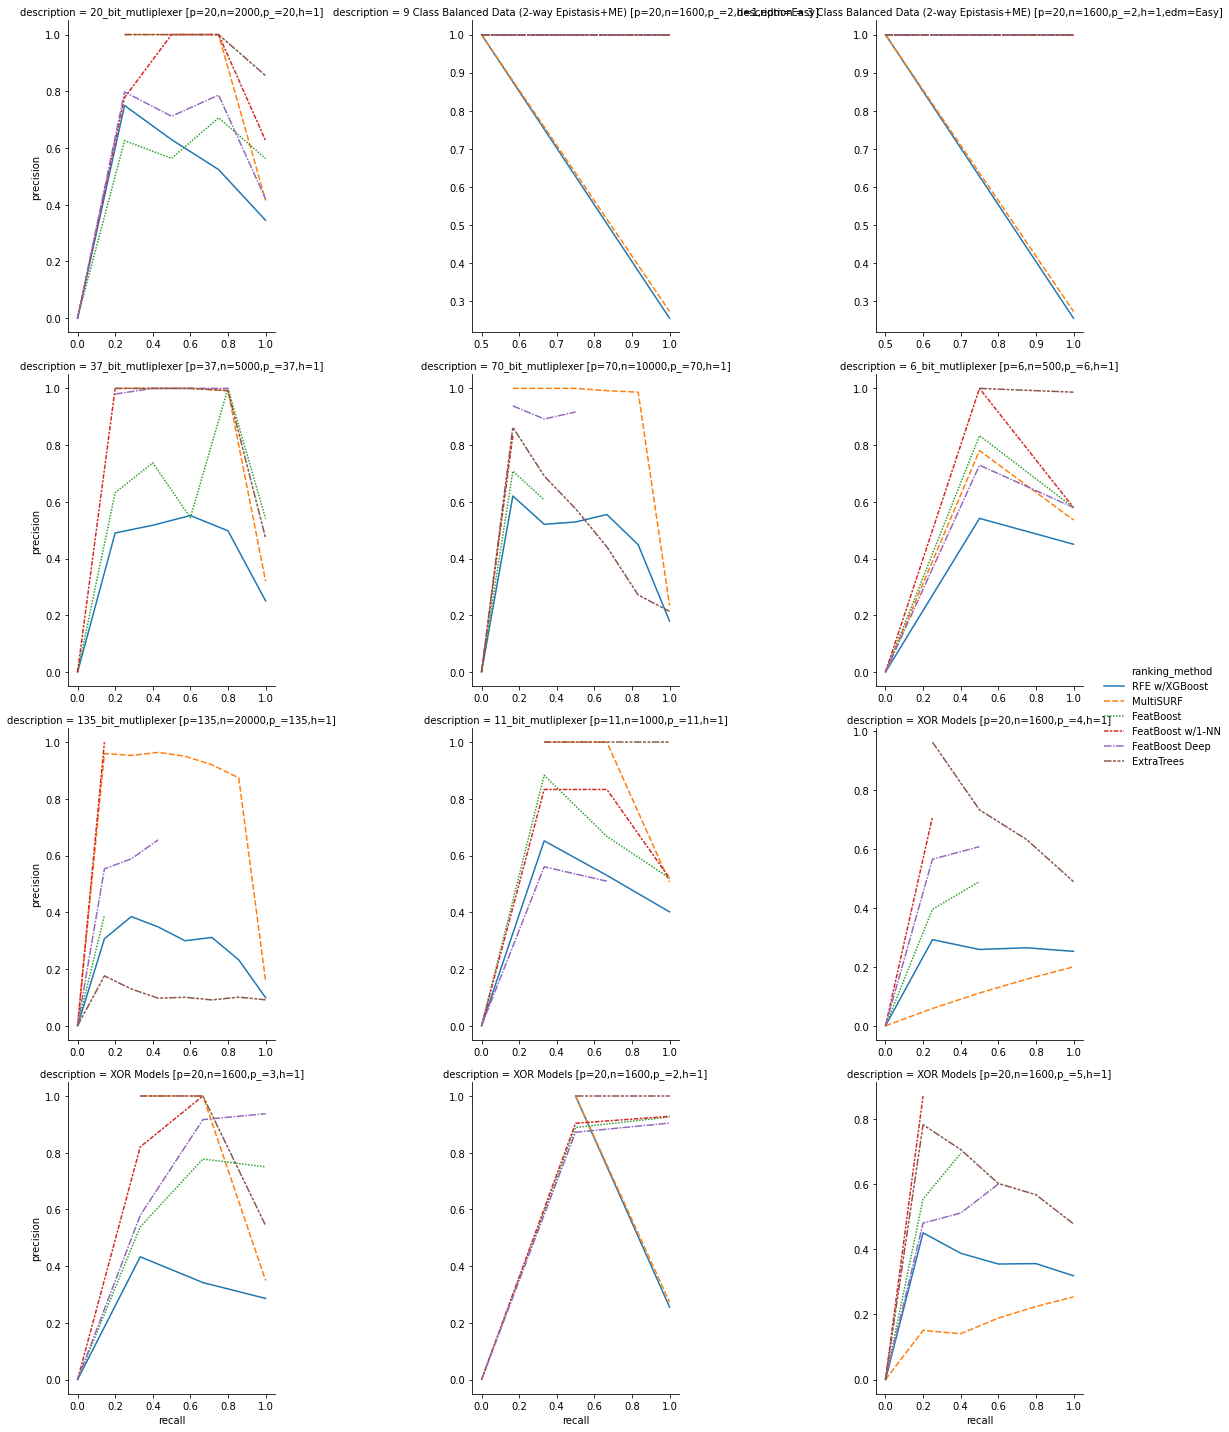

In [33]:
# pr curve
g = sns.relplot(x='recall', y='precision', hue='ranking_method', style='ranking_method',
                col='description', kind='line', err_style=None,
                data=subset, col_wrap=3, facet_kws={'sharex': False, 'sharey': False})
# roc curve
g = sns.relplot(x='recall', y='recall', hue='ranking_method', style='ranking_method',
                col='description', kind='line', err_style=None,
                data=subset, col_wrap=3, facet_kws={'sharex': False, 'sharey': False})

Text(0.5, 1.0, 'recall per ranking method for all datasets')

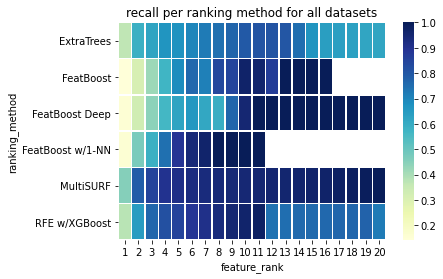

In [21]:
subset2 = subset[subset['feature_rank'] <= 20]

from matplotlib.ticker import FuncFormatter
rectangular = pd.pivot_table(subset2,\
    values='recall',\
    index=['ranking_method'],\
    columns=['feature_rank'])
g = sns.heatmap(rectangular,\
    linewidths=.5, cmap="YlGnBu")
plt.yticks(rotation=0)
plt.xticks(rotation=0)
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: int(x) + 1))
plt.title('recall per ranking method for all datasets')

Construct a sensible subset for plotting

In [55]:
# subset = statdata.copy()
# for dataset, data in statdata.groupby('description'):
#     all_replicas = data.groupby('replica_no')
#     if len(all_replicas.count()) != 24: # only 'finished' datasets
#         subset = subset[subset['description'] != dataset]
#     else: # add newline in plot title
#         descr = dataset.replace(' [p=', '\n[p=')
#         descr = descr.replace(',h=', ',\nh=')
#         subset = subset.replace({ 'description': dataset }, descr)
#         # short_descr = '[p=' + dataset.split(' [p=')[1]
#         # entries = subset[subset['description'] == dataset]
#         # subset.loc[entries.index, 'short_descr'] = short_descr
# subset = subset[subset['feature_rank'] <= 20]
# subset = subset[subset['ranking_method'] != 'Stability Selection']
# subset.shape

(89214, 20)

In [22]:
def draw_heatmap(*args, **kwargs):
    data = kwargs.pop('data')
    rect = pd.pivot_table(data, values='recall',\
                        index=['ranking_method'],\
                        columns=['feature_rank'])
    sns.heatmap(rect, linewidths=.5, cmap="YlGnBu")
    plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: int(x) + 1))
    plt.yticks(rotation=0)
    plt.xticks(rotation=0)

def pltrecall(data, title):
    fg = sns.FacetGrid(data, col='description', sharex=False, col_wrap=3, size=2.75, aspect=2)
    fg.map_dataframe(draw_heatmap).set_titles("{col_name}")
    fg.fig.subplots_adjust(wspace=0.1, hspace=0.5)
    # plt.subplots_adjust(top=0.875)
    # fg.fig.suptitle(title)
    # fg.fig.tight_layout()

for name, data in subset2.groupby('name'):
    pltrecall(data, name)

ValueError: zero-size array to reduction operation fmin which has no identity